# Advantage Actor-Critic (A2C) on CartPole with Stable-Baselines3

In [1]:
import gymnasium as gym
import numpy as np
import time
from matplotlib import pyplot as plt

from stable_baselines3 import A2C
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

## Configuration

These are the default values of SB3's `A2C`, written out so that they are easy to inspect and change.

In [2]:
# Training configuration
ENV_ID = "CartPole-v1"
TOTAL_TIMESTEPS = 200_000
N_ENVS = 8              # parallel copies of the environment
N_STEPS = 5             # steps per copy before each update (n-step return)
GAMMA = 0.99            # discount factor
LEARNING_RATE = 0.0007
ENT_COEF = 0.0          # weight of the entropy bonus (exploration)
VF_COEF = 0.5           # weight of the critic loss
N_EVAL_EPISODES = 100

SEED = 42

## Environment

`CartPole-v1`: four continuous observations (cart position, cart velocity, pole angle, pole angular velocity), two actions (push left or right), and reward $+1$ for every step the pole stays up. Episodes are truncated after 500 steps, and an average return of 475 over 100 episodes counts as solved.

`make_vec_env` creates `N_ENVS` copies of the environment, wraps each one in a `Monitor` that records its episodes, and gives copy $i$ the seed `SEED + i`. A copy that finishes an episode is reset automatically. `reset` returns one observation per copy, so the agent always works with a batch of states.

In [3]:
env = make_vec_env(ENV_ID, n_envs=N_ENVS, seed=SEED)

observations = env.reset()

print("Number of copies:", env.num_envs)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Batch of observations:", observations.shape)
print("Maximum episode steps:", gym.spec(ENV_ID).max_episode_steps)
print("Reward threshold:", gym.spec(ENV_ID).reward_threshold)

Number of copies: 8
Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Batch of observations: (8, 4)
Maximum episode steps: 500
Reward threshold: 475.0


## A2C agent

The constructor receives the hyperparameters from the configuration. With `verbose=1`, SB3 prints a table of training statistics during training.

In [4]:
model = A2C(
    "MlpPolicy",
    env,
    n_steps=N_STEPS,
    gamma=GAMMA,
    learning_rate=LEARNING_RATE,
    ent_coef=ENT_COEF,
    vf_coef=VF_COEF,
    verbose=1,
    seed=SEED,
    device="cpu",
)

print(model.policy)

Using cpu device
ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=4, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=4, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=2, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


The printout shows that the actor and the critic are **two separate networks**, each with two hidden layers of 64 `tanh` units:

* `mlp_extractor.policy_net` followed by `action_net` is the **actor**, which returns two logits;
* `mlp_extractor.value_net` followed by `value_net` is the **critic** $\hat v(s; w)$.

The only shared part is `features_extractor`, which flattens the observation and has no parameters. What the actor and the critic really share is the **loss** $L(\theta, w)$ and the **optimizer**: each step updates $\theta$ and $w$ together.

## Training

`model.learn` repeats the four steps of the algorithm. Each update uses $8 \times 5 = 40$ transitions, so 200,000 environment steps give $200{,}000 / 40 = 5000$ updates. SB3 prints a table every `log_interval` updates; we ask for one every 1000 updates. The most useful entries are:

* `rollout/ep_rew_mean`: mean return of the last 100 training episodes (with sampled actions);
* `train/policy_loss` and `train/value_loss`: the actor and critic terms of $L(\theta, w)$;
* `train/entropy_loss`: minus the entropy of the policy, which moves towards zero as the policy becomes more deterministic;
* `train/explained_variance`: how well the critic predicts the returns ($1$ is perfect, $0$ is no better than a constant).

In [5]:
start_time = time.time()
model.learn(total_timesteps=TOTAL_TIMESTEPS, log_interval=1000)
training_minutes = (time.time() - start_time) / 60

print(f"Training time: {training_minutes:.2f} minutes")
print(f"Environment steps: {model.num_timesteps}")
print(f"Updates: {model.num_timesteps // (N_ENVS * N_STEPS)}")

------------------------------------
| rollout/              |          |
|    ep_len_mean        | 271      |
|    ep_rew_mean        | 271      |
| time/                 |          |
|    fps                | 20990    |
|    iterations         | 1000     |
|    time_elapsed       | 1        |
|    total_timesteps    | 40000    |
| train/                |          |
|    entropy_loss       | -0.509   |
|    explained_variance | 0.363    |
|    learning_rate      | 0.0007   |
|    n_updates          | 999      |
|    policy_loss        | 0.926    |
|    value_loss         | 2.21     |
------------------------------------
------------------------------------
| rollout/              |          |
|    ep_len_mean        | 348      |
|    ep_rew_mean        | 348      |
| time/                 |          |
|    fps                | 20959    |
|    iterations         | 2000     |
|    time_elapsed       | 3        |
|    total_timesteps    | 80000    |
| train/                |          |
|

## Learning curve

Each copy has its own `Monitor`. The copies step together, so when one copy has taken $k$ steps, all the copies together have taken $N_\text{ENVS} \cdot k$ steps. We merge the episodes of the 8 copies in the order in which they ended and plot their returns against the total number of environment steps.

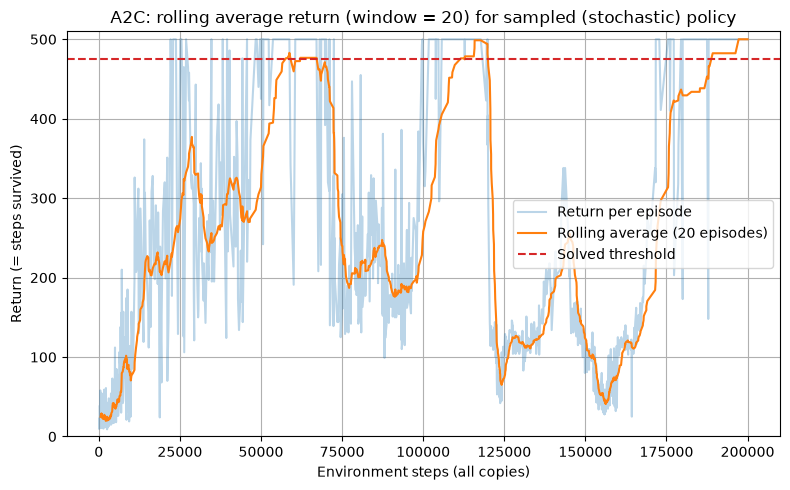

Training episodes: 1109


In [6]:
episode_returns = []
episode_end_steps = []

for returns, lengths in zip(
    env.env_method("get_episode_rewards"),
    env.env_method("get_episode_lengths"),
):
    episode_returns.extend(returns)
    episode_end_steps.extend(N_ENVS * np.cumsum(lengths))

order = np.argsort(episode_end_steps)
episode_returns = np.array(episode_returns)[order]
episode_end_steps = np.array(episode_end_steps)[order]

window = 20
rolling_returns = np.convolve(episode_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 5))
plt.plot(episode_end_steps, episode_returns, alpha=0.3, label="Return per episode")
plt.plot(episode_end_steps[window - 1:], rolling_returns, label=f"Rolling average ({window} episodes)")
plt.axhline(475, color="tab:red", linestyle="--", label="Solved threshold")
plt.xlabel("Environment steps (all copies)")
plt.ylabel("Return (= steps survived)")
plt.ylim(0, 510)
plt.title(f"A2C: rolling average return (window = {window}) for sampled (stochastic) policy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Training episodes: {len(episode_returns)}")

## Evaluate the policy

`evaluate_policy` from SB3 plays complete episodes and returns their returns. As in the previous notebooks, we evaluate the trained policy over 100 episodes in two ways:

1. **greedy**: `deterministic=True`, the most probable action;
2. **sampled**: `deterministic=False`, as during training.

Each evaluation uses a new environment seeded with `SEED + 1000`, so both face the same 100 starting states.

In [7]:
def evaluate(deterministic):
    """Return the returns of N_EVAL_EPISODES evaluation episodes."""
    eval_env = Monitor(gym.make(ENV_ID))
    eval_env.reset(seed=SEED + 1000)  # later resets continue from this seed
    returns, lengths = evaluate_policy(
        model,
        eval_env,
        n_eval_episodes=N_EVAL_EPISODES,
        deterministic=deterministic,
        return_episode_rewards=True,
    )
    eval_env.close()
    return np.array(returns)


greedy_returns = evaluate(deterministic=True)
sampled_returns = evaluate(deterministic=False)

for name, returns in [
    ("greedy ", greedy_returns),
    ("sampled", sampled_returns),
]:
    print(
        f"{name}: mean {returns.mean():6.1f} | std {returns.std():6.1f} | "
        f"min {returns.min():4.0f} | max {returns.max():4.0f} | "
        f"solved (mean >= 475): {returns.mean() >= 475}"
    )

greedy : mean  500.0 | std    0.0 | min  500 | max  500 | solved (mean >= 475): True
sampled: mean  500.0 | std    0.0 | min  500 | max  500 | solved (mean >= 475): True


## One greedy rollout

As in the DQN notebook, we record one greedy episode and plot two important state variables. A successful policy keeps both the cart position and the pole angle inside the red limits for 500 steps.

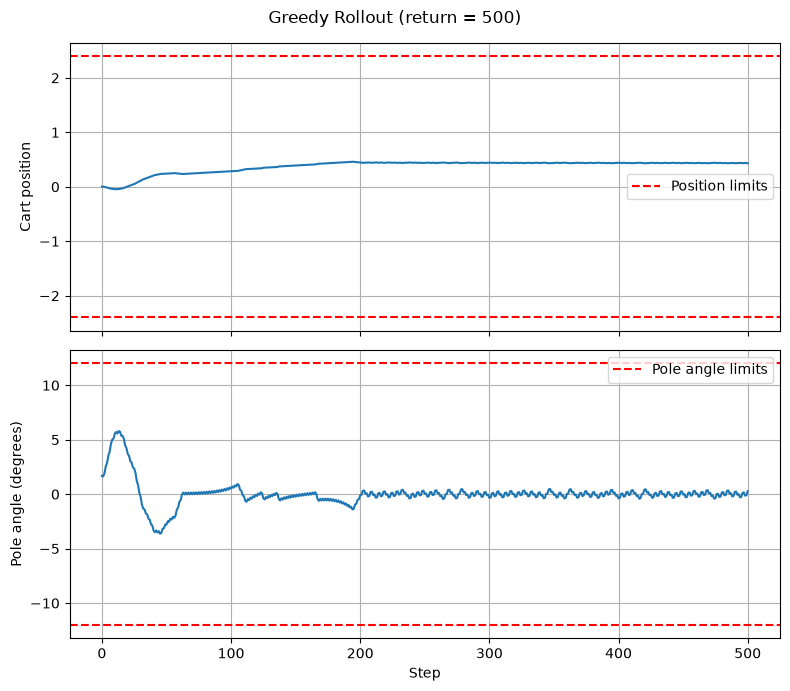

Rollout return: 500
Rollout steps:  500


In [8]:
rollout_env = gym.make(ENV_ID)
state, info = rollout_env.reset(seed=SEED + 2000)
rollout_states = [state.copy()]
rollout_return = 0.0

for step in range(rollout_env.spec.max_episode_steps):
    action, _ = model.predict(state, deterministic=True)
    state, reward, terminated, truncated, info = rollout_env.step(int(action))
    rollout_states.append(state.copy())
    rollout_return += reward

    if terminated or truncated:
        break

rollout_states = np.array(rollout_states)
time_steps = np.arange(len(rollout_states))

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
axes[0].plot(time_steps, rollout_states[:, 0])
axes[0].axhline(-2.4, color="red", linestyle="--", label="Position limits")
axes[0].axhline(2.4, color="red", linestyle="--")
axes[0].set_ylabel("Cart position")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(time_steps, np.degrees(rollout_states[:, 2]))
axes[1].axhline(-12.0, color="red", linestyle="--", label="Pole angle limits")
axes[1].axhline(12.0, color="red", linestyle="--")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Pole angle (degrees)")
axes[1].grid(True)
axes[1].legend()

fig.suptitle(f"Greedy Rollout (return = {rollout_return:.0f})")
fig.tight_layout()
plt.show()

print(f"Rollout return: {rollout_return:.0f}")
print(f"Rollout steps:  {len(rollout_states) - 1}")

## Save the trained agent

`model.save` writes a `.zip` file with the actor, the critic and the hyperparameters, and `A2C.load` rebuilds the whole agent from it. We check that the reloaded agent chooses the same greedy action.

To watch the saved agent, run from this folder:

```
python run_a2c_cartpole_policy.py --episodes 3
```

In [9]:
MODEL_PATH = "a2c_cartpole_policy"
model.save(MODEL_PATH)  # writes a2c_cartpole_policy.zip

# Check that the saved agent can be loaded.
check_model = A2C.load(MODEL_PATH, device="cpu")

check_state, info = rollout_env.reset(seed=SEED + 3000)
original_action, _ = model.predict(check_state, deterministic=True)
reloaded_action, _ = check_model.predict(check_state, deterministic=True)

print("Saved and reloaded:", MODEL_PATH + ".zip")
print("Greedy actions match:", bool(original_action == reloaded_action))
env.close()
rollout_env.close()

Saved and reloaded: a2c_cartpole_policy.zip
Greedy actions match: True
